In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
df = pd.read_csv("heart.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [4]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Column Names:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope', 'HeartDisease']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB

Missing Valu

In [5]:
print(df["HeartDisease"].value_counts())

print("\nTarget Percentage:")
print(df["HeartDisease"].value_counts(normalize=True) * 100)

HeartDisease
1    508
0    410
Name: count, dtype: int64

Target Percentage:
HeartDisease
1    55.337691
0    44.662309
Name: proportion, dtype: float64


In [6]:
X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS', 'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope']

Target:
HeartDisease


In [7]:
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_columns = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nNumerical Columns:")
print(numerical_columns)

Categorical Columns:
['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Numerical Columns:
['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']


In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        )
    ],
    remainder="passthrough"
)

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 734
Testing samples: 184


In [10]:
bagging_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", BaggingClassifier(
        estimator=DecisionTreeClassifier(random_state=42),
        n_estimators=100,
        random_state=42
    ))
])

bagging_model.fit(X_train, y_train)

y_pred_bagging = bagging_model.predict(X_test)

In [11]:
print("BAGGING CLASSIFIER")
print("------------------")

print("Accuracy :", accuracy_score(y_test, y_pred_bagging))
print("Precision:", precision_score(y_test, y_pred_bagging))
print("Recall   :", recall_score(y_test, y_pred_bagging))
print("F1 Score :", f1_score(y_test, y_pred_bagging))

BAGGING CLASSIFIER
------------------
Accuracy : 0.8641304347826086
Precision: 0.8666666666666667
Recall   : 0.8921568627450981
F1 Score : 0.8792270531400966


In [12]:
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

In [13]:
print("RANDOM FOREST")
print("-------------")

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall   :", recall_score(y_test, y_pred_rf))
print("F1 Score :", f1_score(y_test, y_pred_rf))

RANDOM FOREST
-------------
Accuracy : 0.9021739130434783
Precision: 0.8962264150943396
Recall   : 0.9313725490196079
F1 Score : 0.9134615384615384


In [14]:
ada_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", AdaBoostClassifier(
        n_estimators=100,
        random_state=42
    ))
])

ada_model.fit(X_train, y_train)

y_pred_ada = ada_model.predict(X_test)

In [15]:
print("ADABOOST")
print("--------")

print("Accuracy :", accuracy_score(y_test, y_pred_ada))
print("Precision:", precision_score(y_test, y_pred_ada))
print("Recall   :", recall_score(y_test, y_pred_ada))
print("F1 Score :", f1_score(y_test, y_pred_ada))

ADABOOST
--------
Accuracy : 0.8804347826086957
Precision: 0.8921568627450981
Recall   : 0.8921568627450981
F1 Score : 0.8921568627450981


In [16]:
gb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

y_pred_gb = gb_model.predict(X_test)

In [17]:
print("GRADIENT BOOSTING")
print("-----------------")

print("Accuracy :", accuracy_score(y_test, y_pred_gb))
print("Precision:", precision_score(y_test, y_pred_gb))
print("Recall   :", recall_score(y_test, y_pred_gb))
print("F1 Score :", f1_score(y_test, y_pred_gb))

GRADIENT BOOSTING
-----------------
Accuracy : 0.8913043478260869
Precision: 0.9019607843137255
Recall   : 0.9019607843137255
F1 Score : 0.9019607843137255


In [18]:
results = {
    "Bagging": y_pred_bagging,
    "Random Forest": y_pred_rf,
    "AdaBoost": y_pred_ada,
    "Gradient Boosting": y_pred_gb
}

comparison = []

for model_name, predictions in results.items():

    comparison.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(comparison)

comparison_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Bagging,0.864130,0.866667,0.892157,0.879227
1,Random Forest,0.902174,0.896226,0.931373,0.913462
2,AdaBoost,0.880435,0.892157,0.892157,0.892157
3,Gradient Boosting,0.891304,0.901961,0.901961,0.901961


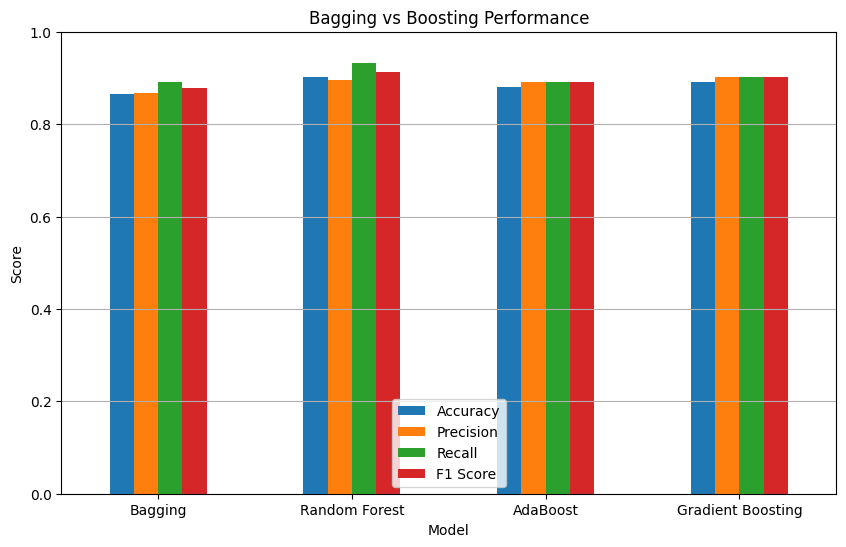

In [19]:
comparison_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Bagging vs Boosting Performance")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

In [20]:
for model_name, predictions in results.items():

    print("\n")
    print("=" * 60)
    print(model_name)
    print("=" * 60)

    print(
        classification_report(
            y_test,
            predictions,
            target_names=["No Disease", "Heart Disease"]
        )
    )



Bagging
               precision    recall  f1-score   support

   No Disease       0.86      0.83      0.84        82
Heart Disease       0.87      0.89      0.88       102

     accuracy                           0.86       184
    macro avg       0.86      0.86      0.86       184
 weighted avg       0.86      0.86      0.86       184



Random Forest
               precision    recall  f1-score   support

   No Disease       0.91      0.87      0.89        82
Heart Disease       0.90      0.93      0.91       102

     accuracy                           0.90       184
    macro avg       0.90      0.90      0.90       184
 weighted avg       0.90      0.90      0.90       184



AdaBoost
               precision    recall  f1-score   support

   No Disease       0.87      0.87      0.87        82
Heart Disease       0.89      0.89      0.89       102

     accuracy                           0.88       184
    macro avg       0.88      0.88      0.88       184
 weighted avg       

In [21]:
final_table = comparison_df.copy()

for column in ["Accuracy", "Precision", "Recall", "F1 Score"]:
    final_table[column] = (
        final_table[column] * 100
    ).round(2)

final_table

,Model,Accuracy,Precision,Recall,F1 Score
0,Bagging,86.41,86.67,89.22,87.92
1,Random Forest,90.22,89.62,93.14,91.35
2,AdaBoost,88.04,89.22,89.22,89.22
3,Gradient Boosting,89.13,90.20,90.20,90.20
